# Postergación del etiquetado en una viña
### Planificación de embotellado y etiquetado bajo demanda incierta

Modelo MILP estocástico multietapa sobre un **árbol de 11 escenarios en 3 periodos**, resuelto con **PuLP + HiGHS**.
La pregunta es **cuántos productos conviene embotellar sin etiqueta y etiquetar más tarde** (postergación), una vez que se conoce la demanda.

| Política | Idea |
|---|---|
| **A stock** | Todo se embotella y etiqueta de una vez (`PL = 0`). |
| **Híbrida** | Hasta `PL` productos pueden quedar sin etiqueta y etiquetarse después. |
| **Contra pedido** | No se guarda producto terminado; solo se produce lo que se pide. |

**Contenido:** 1. Datos · 2. Solución de la política base · 3. Comparación de políticas · 4. Sensibilidad · 5. Conclusiones

*Fuentes:* `formulacion_compacta.pdf` (modelo) y `Anexo a Datos.pdf` (instancia).

In [1]:
import importlib, datos, modelo
importlib.reload(datos); importlib.reload(modelo)
import pandas as pd
from IPython.display import display, Markdown
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

---
## 1. Datos de la instancia (Anexo A)
### 1.1 Árbol de escenarios y demanda
Cada nodo es un escenario posible. Su probabilidad **π** es el producto de las probabilidades condicionales desde la raíz (nodo 1).

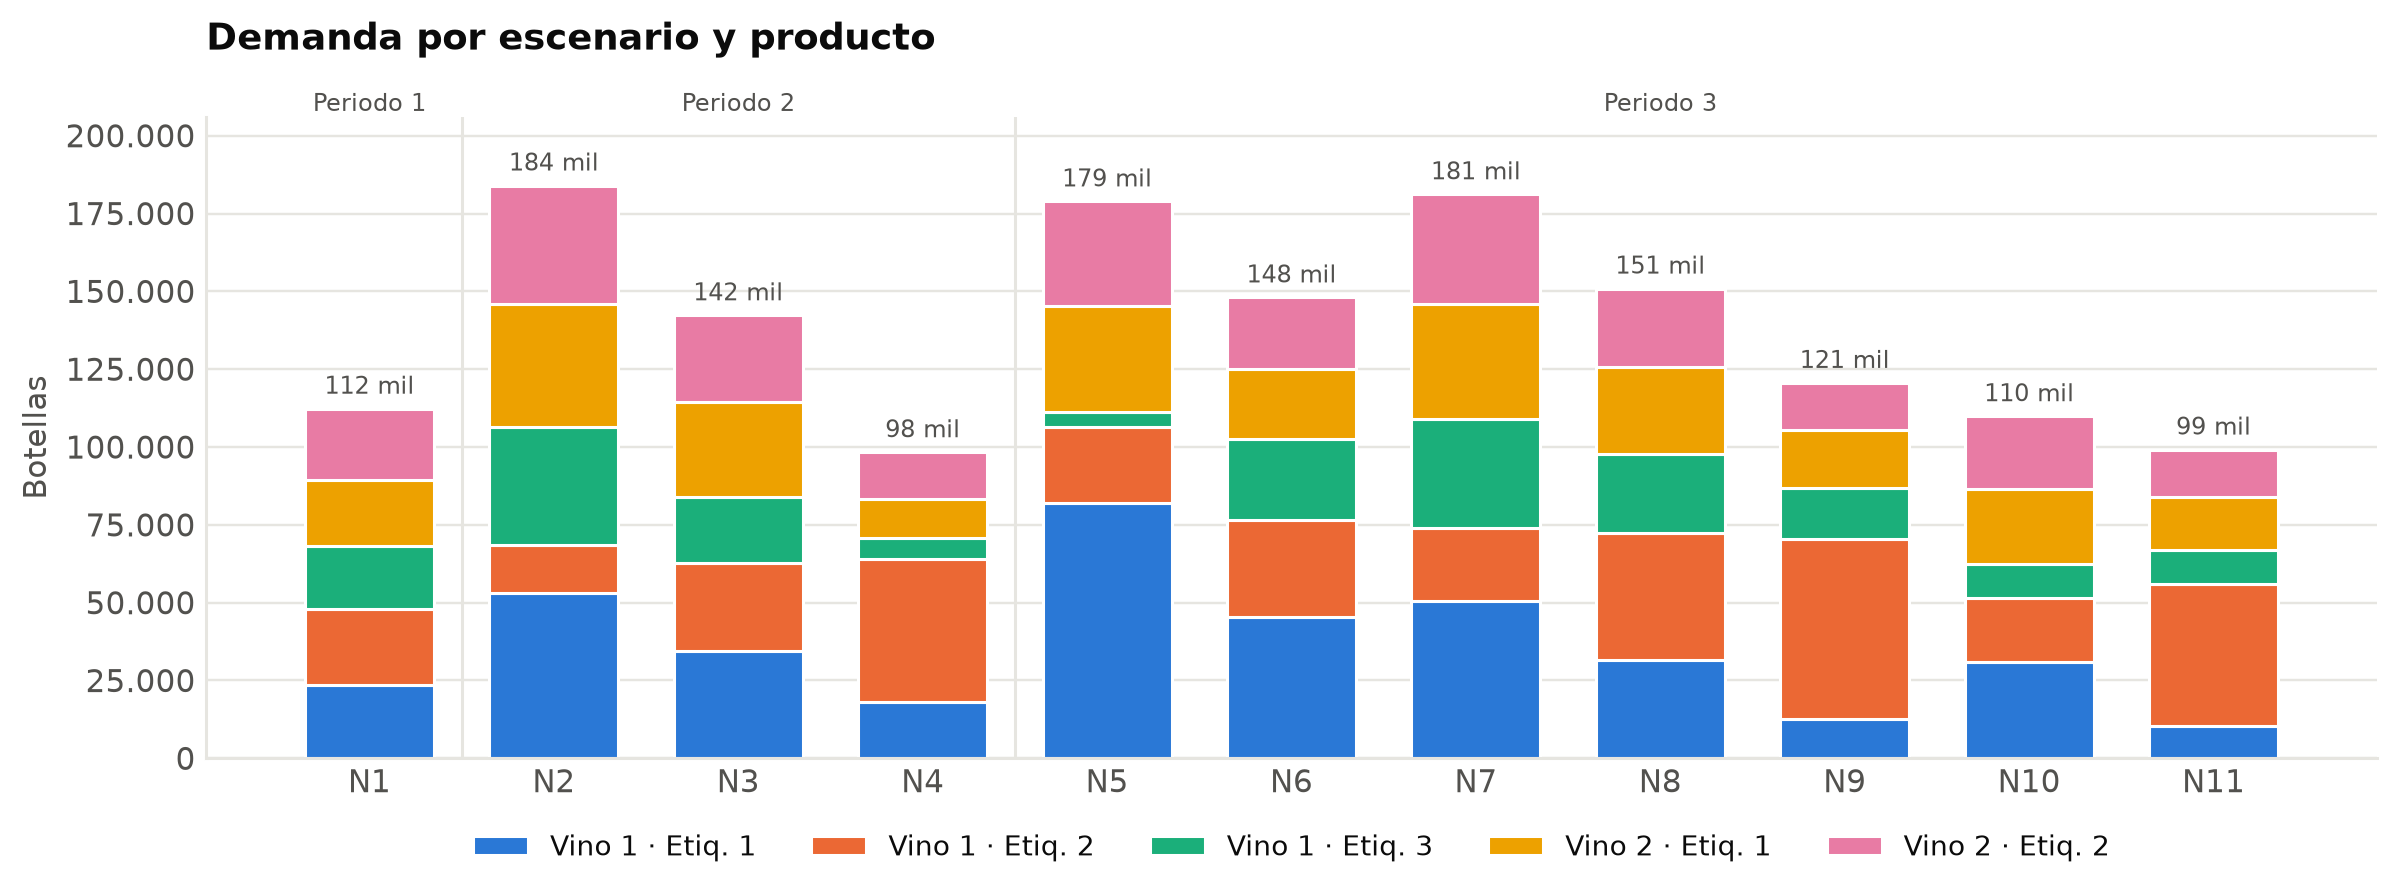

In [2]:
modelo.graficar_demanda();

In [3]:
arbol = pd.DataFrame({'Periodo': modelo._periodos(datos.PADRE), 'Nodo padre': datos.PADRE, 'Probabilidad π': datos.PROB})
arbol['Nodo padre'] = arbol['Nodo padre'].map(lambda p: '—' if pd.isna(p) else f'N{int(p)}')
demanda = pd.Series(datos.DEM).unstack(2)
demanda.index = [modelo._nombre_producto(i, j) for i, j in demanda.index]
demanda.columns = [f'N{n}' for n in demanda.columns]
display(arbol.rename_axis('Nodo').style.format({'Probabilidad π': '{:.3f}'}))
display(demanda.style.format(modelo._num).set_caption('Demanda (botellas) por producto y nodo'))

,Periodo,Nodo padre,Probabilidad π
Nodo,,,
1,1,—,1.000
2,2,N1,0.300
3,2,N1,0.400
4,2,N1,0.300
5,3,N2,0.210
6,3,N2,0.090
7,3,N3,0.133
8,3,N3,0.133
9,3,N3,0.133


,N1,N2,N3,N4,N5,N6,N7,N8,N9,N10,N11
Vino 1 · Etiq. 1,23.525,53.218,34.328,18.118,81.856,45.302,50.426,31.482,12.538,30.856,10.426
Vino 1 · Etiq. 2,24.328,15.184,28.525,45.832,24.546,31.371,23.569,40.767,57.965,20.546,45.569
Vino 1 · Etiq. 3,20.368,38.150,21.080,6.762,4.920,25.765,35.043,25.646,16.248,10.920,11.043
Vino 2 · Etiq. 1,21.080,39.387,30.368,12.646,34.115,22.773,37.045,27.831,18.616,24.115,17.045
Vino 2 · Etiq. 2,22.991,38.048,27.991,14.949,33.440,22.824,35.085,25.147,15.209,23.440,15.085


### 1.2 Parámetros del modelo (Tabla 2)

In [4]:
modelo.tabla_parametros(datos.PARAMS)

,Descripción,Valor
Parámetro,,
T_prod,Horas de línea por periodo,84
K_tank,Estanques disponibles por periodo,20
V_tank,Litros por estanque,10.000
V_bot,Litros por botella,"0,75"
U,Fracción máx. de estanque sin usar,1
Tz_b,Set-up embotellado sin etiqueta (h),"1,5"
Tz_bl,Set-up embotellado + etiquetado (h),"1,5"
Tz_l,Set-up etiquetado posterior (h),"0,5"
Tw_b,Horas por botella sin etiqueta,"0,00014"


---
## 2. Solución de la política base: híbrida con `PL = 2`
Se permite postergar el etiquetado de hasta **2 productos**. El modelo elige cuáles.

In [5]:
res = modelo.resolver(PL=2)
modelo.resumen(res)

Política: Híbrida PL=2  |  estado: Optimal  |  costo esperado: $1.071.131
  Set-ups $13.100  |  Inventario $1.058.031  |  Atrasos $0
  Productos postergables elegidos: Vino 1 · Etiq. 1, Vino 1 · Etiq. 2


### 2.1 Plan del primer periodo (decisión *aquí y ahora*)
Es lo que se ejecuta hoy. Las decisiones de los periodos siguientes dependen del escenario que ocurra.

In [6]:
modelo.tabla_plan_inicial(res)

,Demanda,Botellas a producir,Postergable
Producto,,,
Vino 1 · Etiq. 1,23.525,0,Sí
Vino 1 · Etiq. 2,24.328,0,Sí
Vino 1 · Etiq. 3,20.368,38.150,No
Vino 2 · Etiq. 1,21.080,39.387,No
Vino 2 · Etiq. 2,22.991,38.048,No
Vino 1 · sin etiqueta,,68.402,
Vino 2 · sin etiqueta,,0,


### 2.2 Árbol de escenarios
Más oscuro = la línea trabaja más cerca de su capacidad.

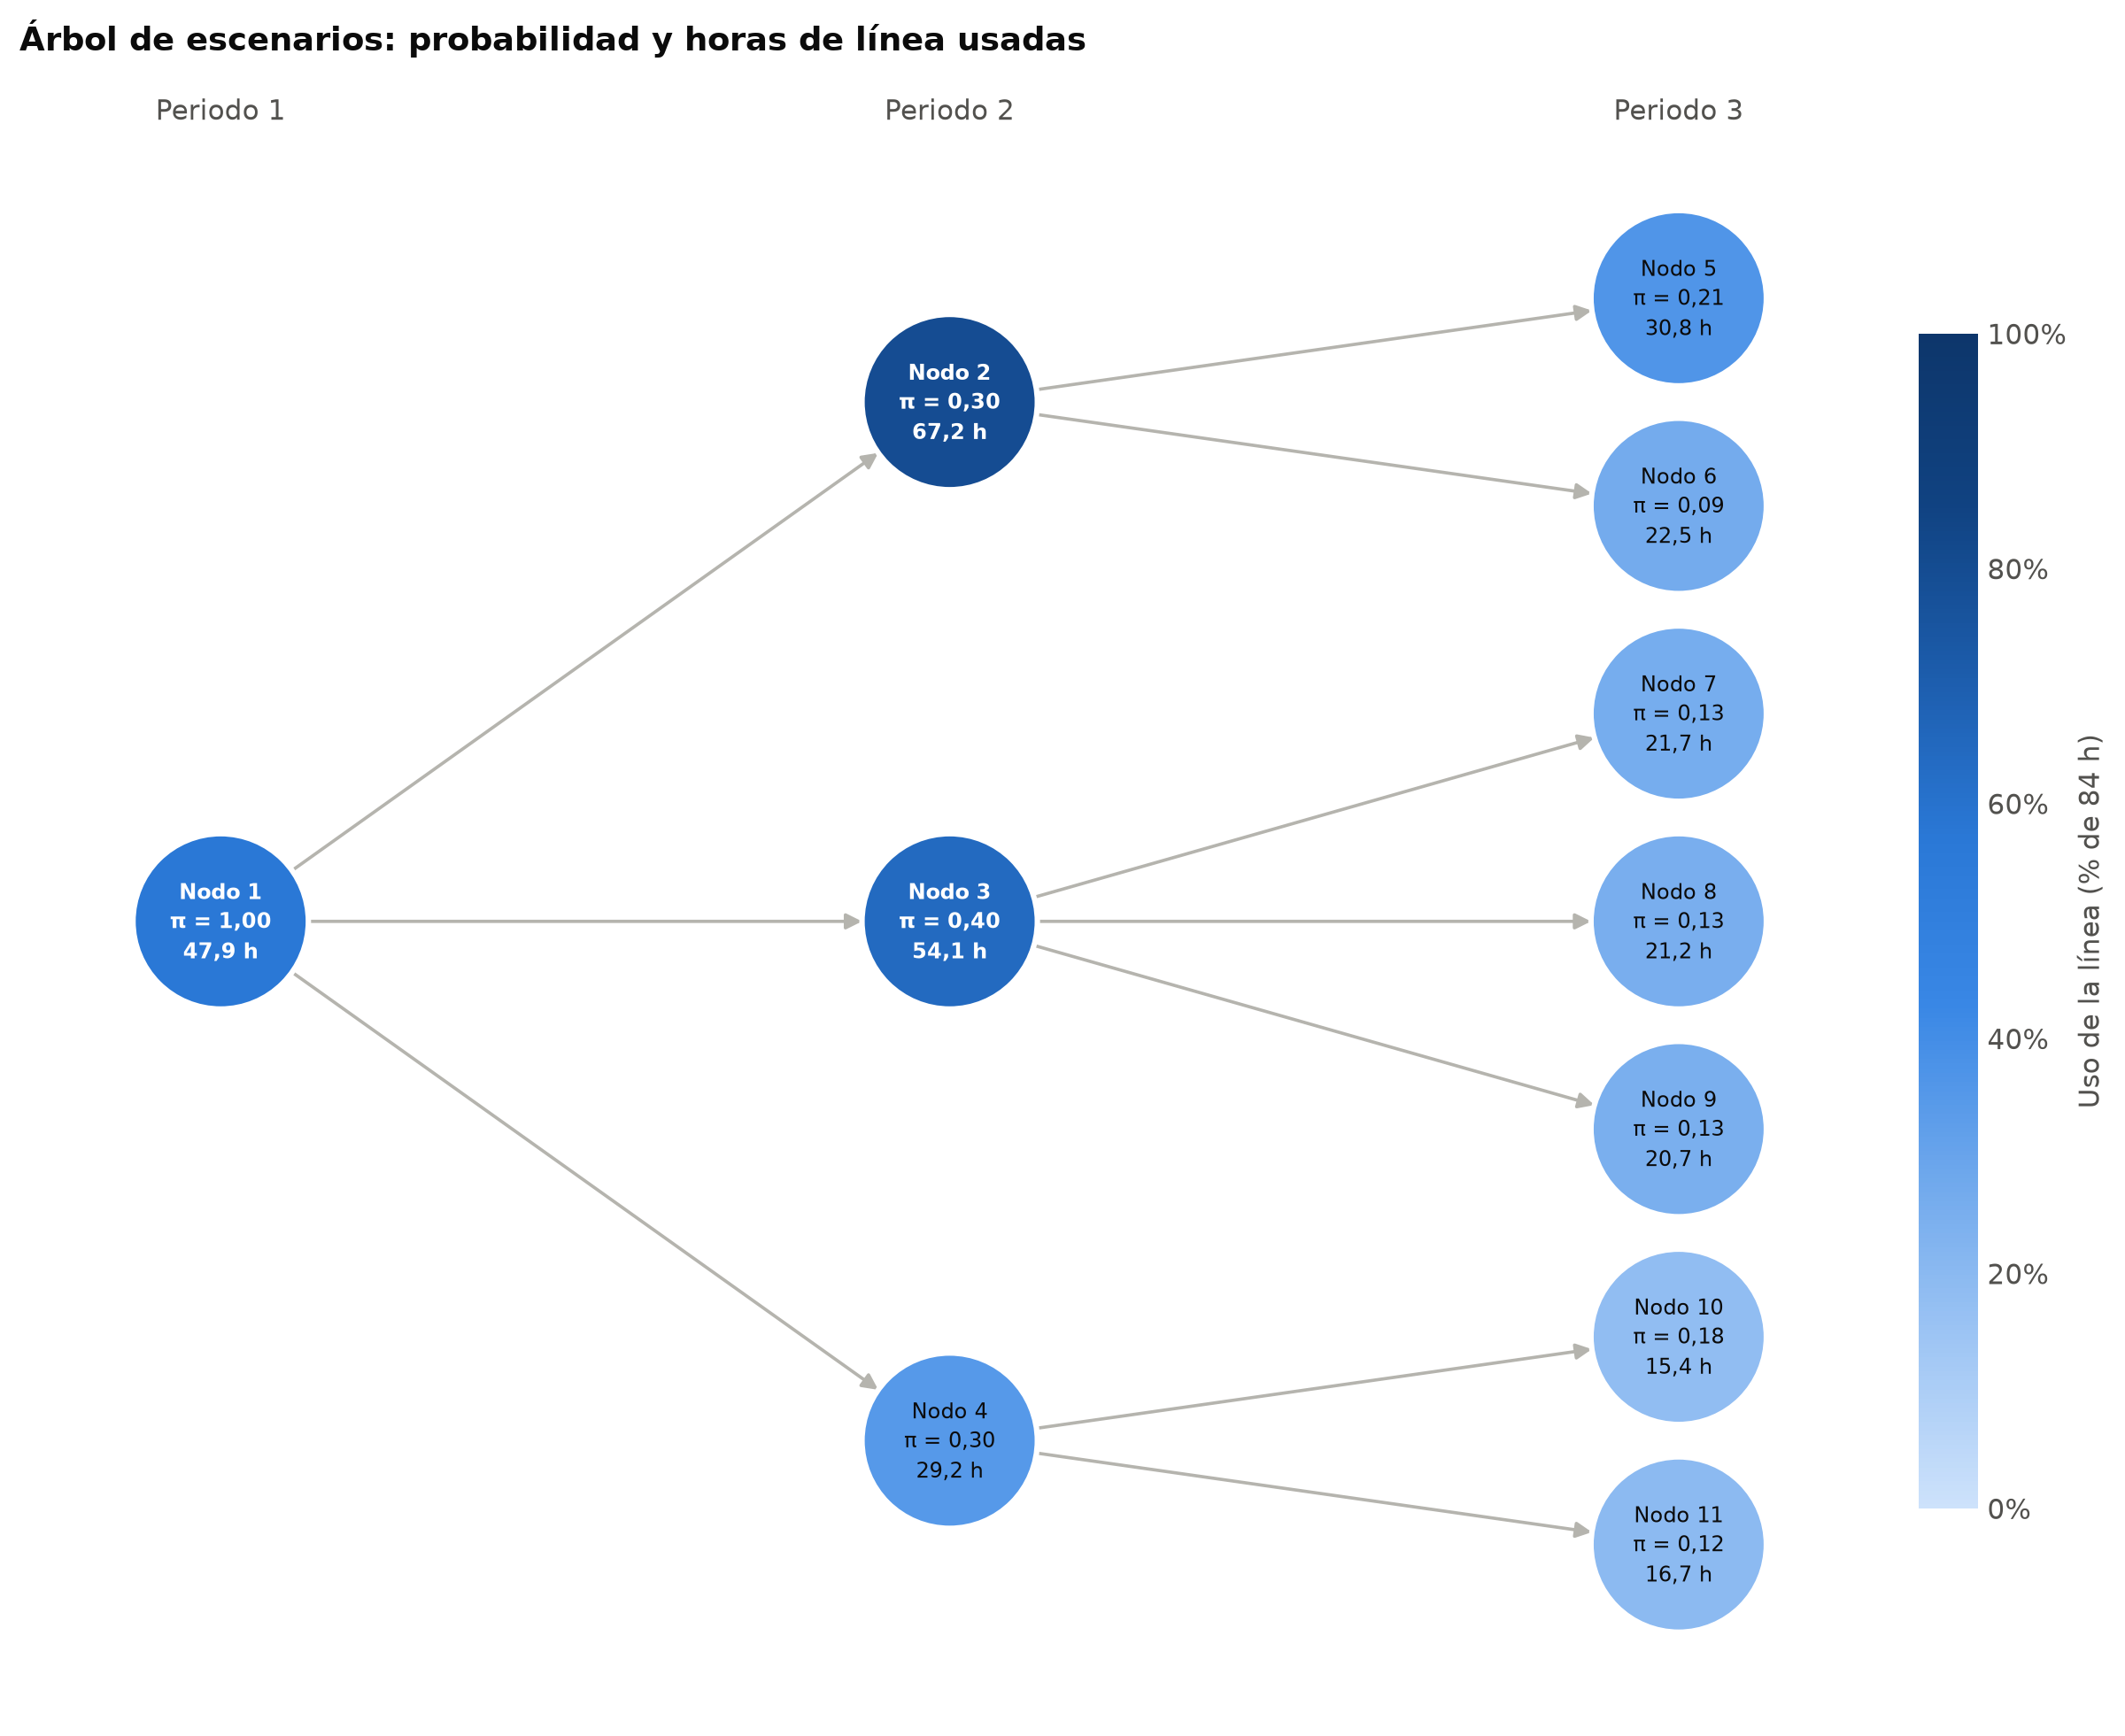

In [7]:
modelo.graficar_arbol(res);

### 2.3 Decisiones por nodo

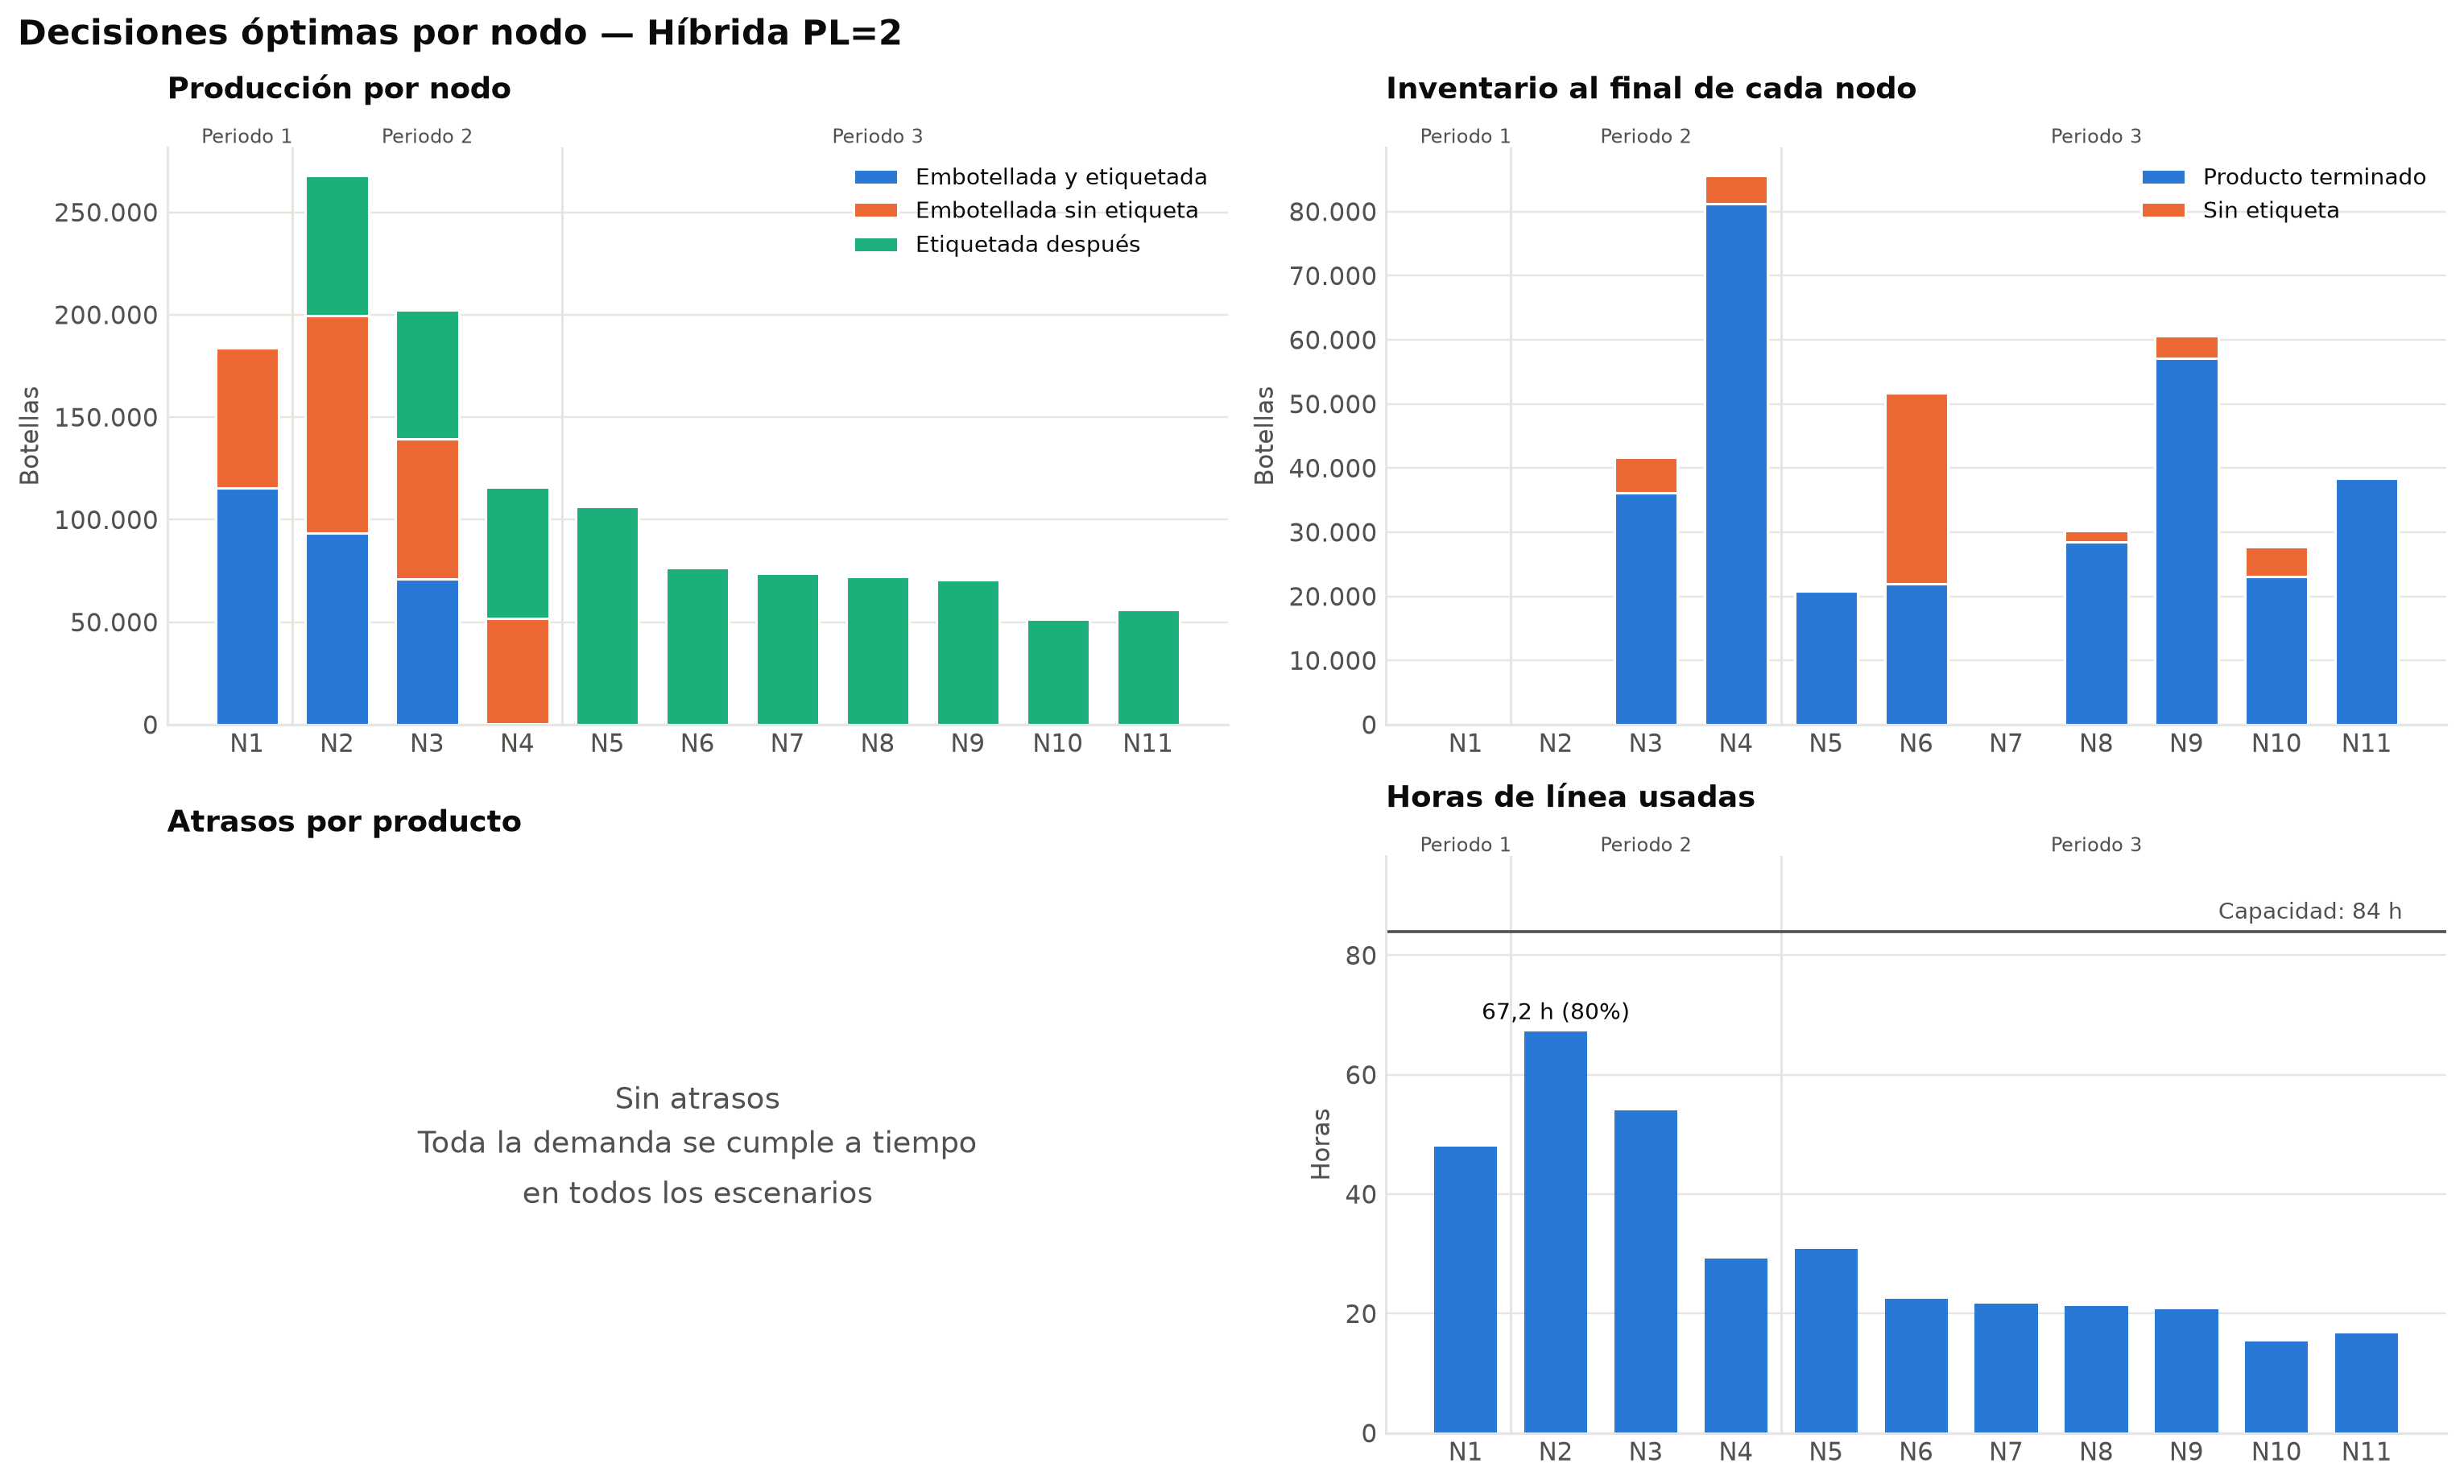

In [8]:
modelo.graficar_decisiones(res);

---
## 3. Comparación de políticas
A stock, híbridas con `PL = 2…5` y contra pedido, sobre el mismo árbol de escenarios. Se destaca la de menor costo.

In [9]:
tabla = modelo.comparar_politicas()
modelo.tabla_comparacion(tabla)

,Costo esperado ($),Set-ups ($),Inventario ($),Atrasos ($),vs. A stock,Productos postergables
Política,,,,,,
A stock,1.918.302,13.650,1.904.652,0,—,—
Híbrida PL=2,1.071.131,13.100,1.058.031,0,−44 %,"V1E1, V1E2"
Híbrida PL=3,793.479,11.550,781.929,0,−59 %,"V1E1, V1E2, V1E3"
Híbrida PL=4,704.616,12.550,692.066,0,−63 %,"V1E1, V1E2, V1E3, V2E1"
Híbrida PL=5,617.164,10.550,606.614,0,−68 %,"V1E1, V1E2, V1E3, V2E1, V2E2"
Contra pedido,1.861.097.600,15.000,0,1.861.082.600,+96.918 %,—


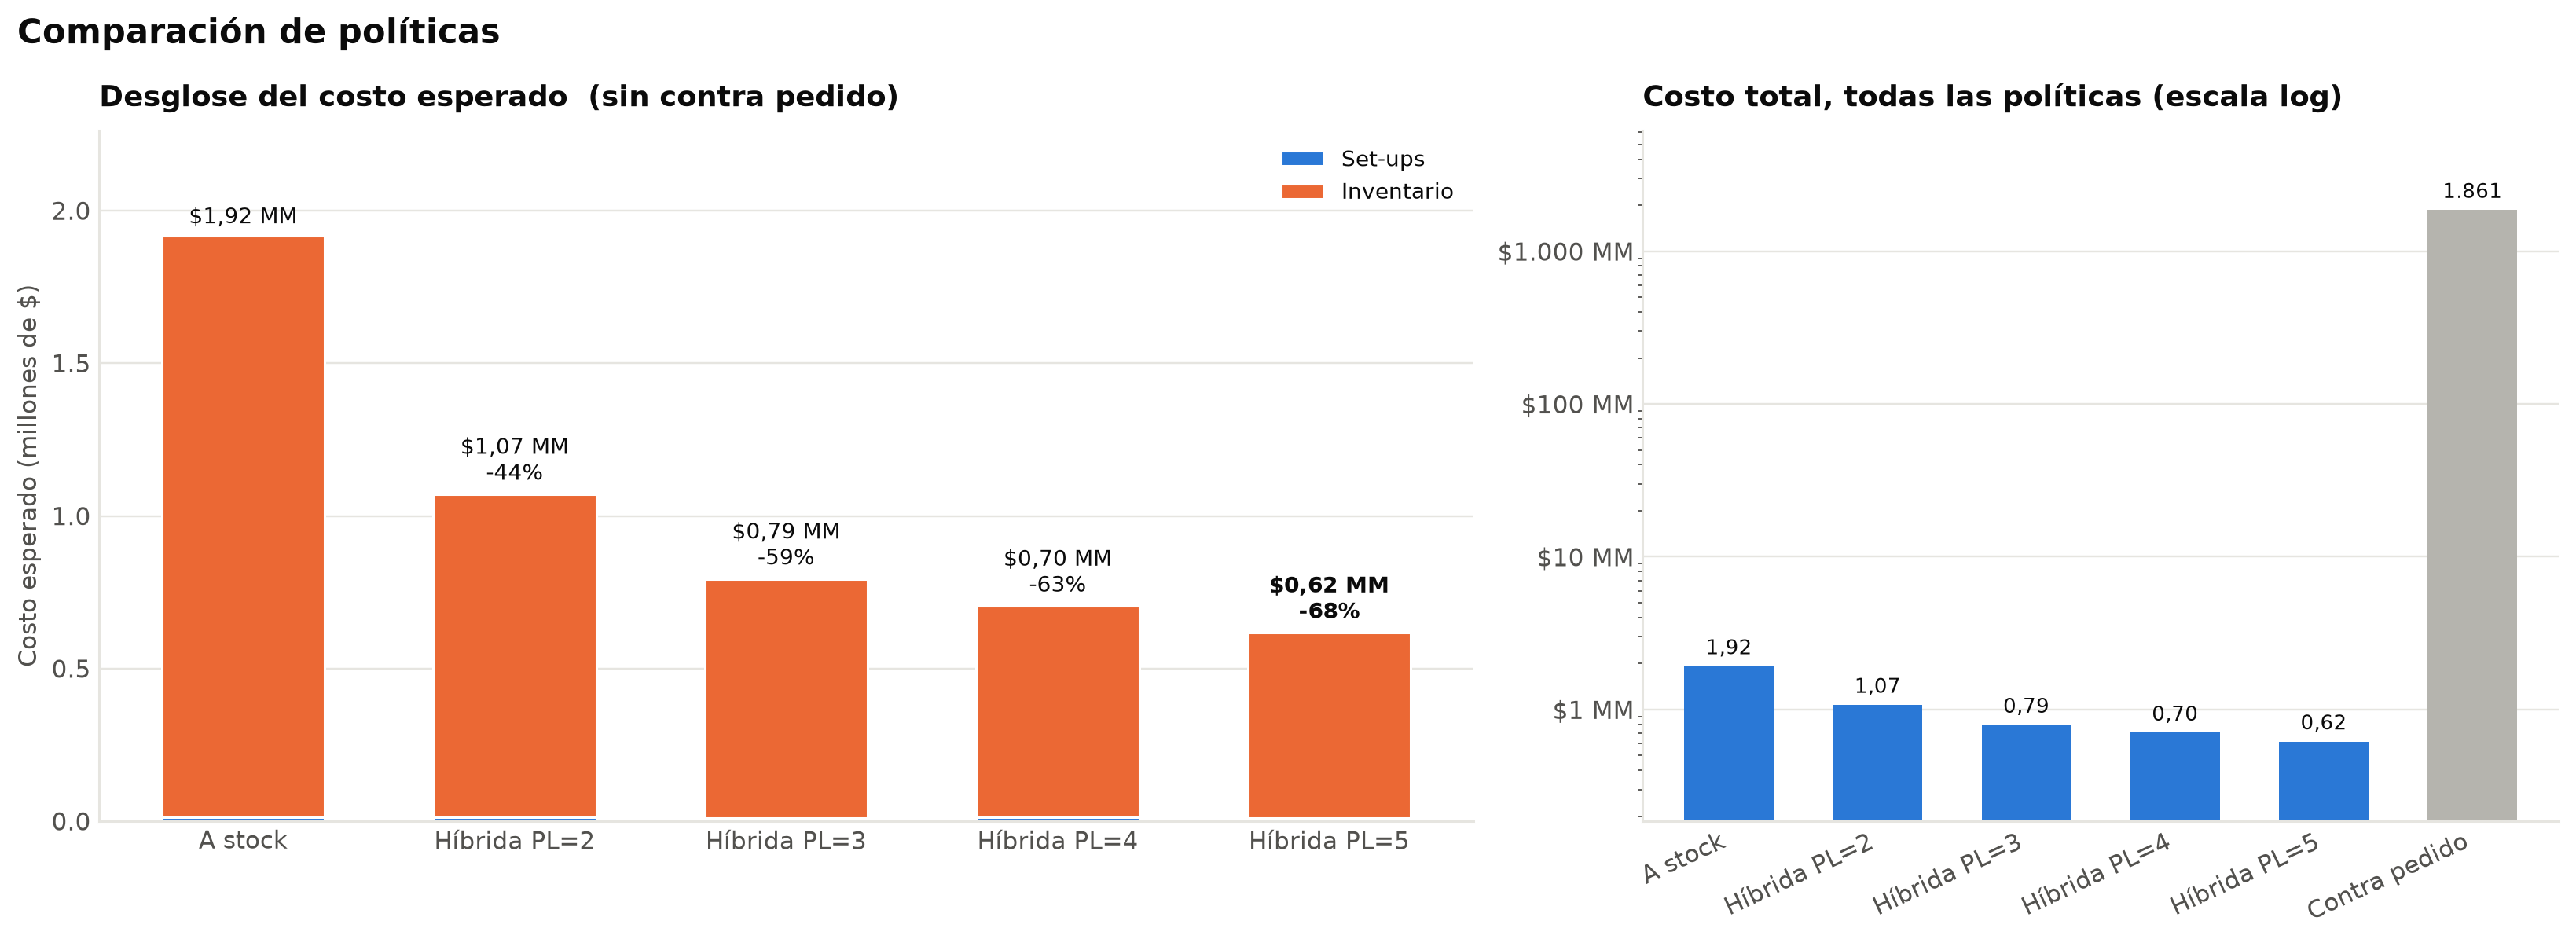

In [10]:
modelo.graficar_comparacion(tabla);

---
## 4. Sensibilidad: capacidad de la línea (`T_prod`)
Se evalúan los **niveles de referencia del Anexo A (sección 6)**: capacidad de **21, 42, 63 y 84 horas** por periodo y **0, 2, 3, 4 y 5** etiquetas postergables.

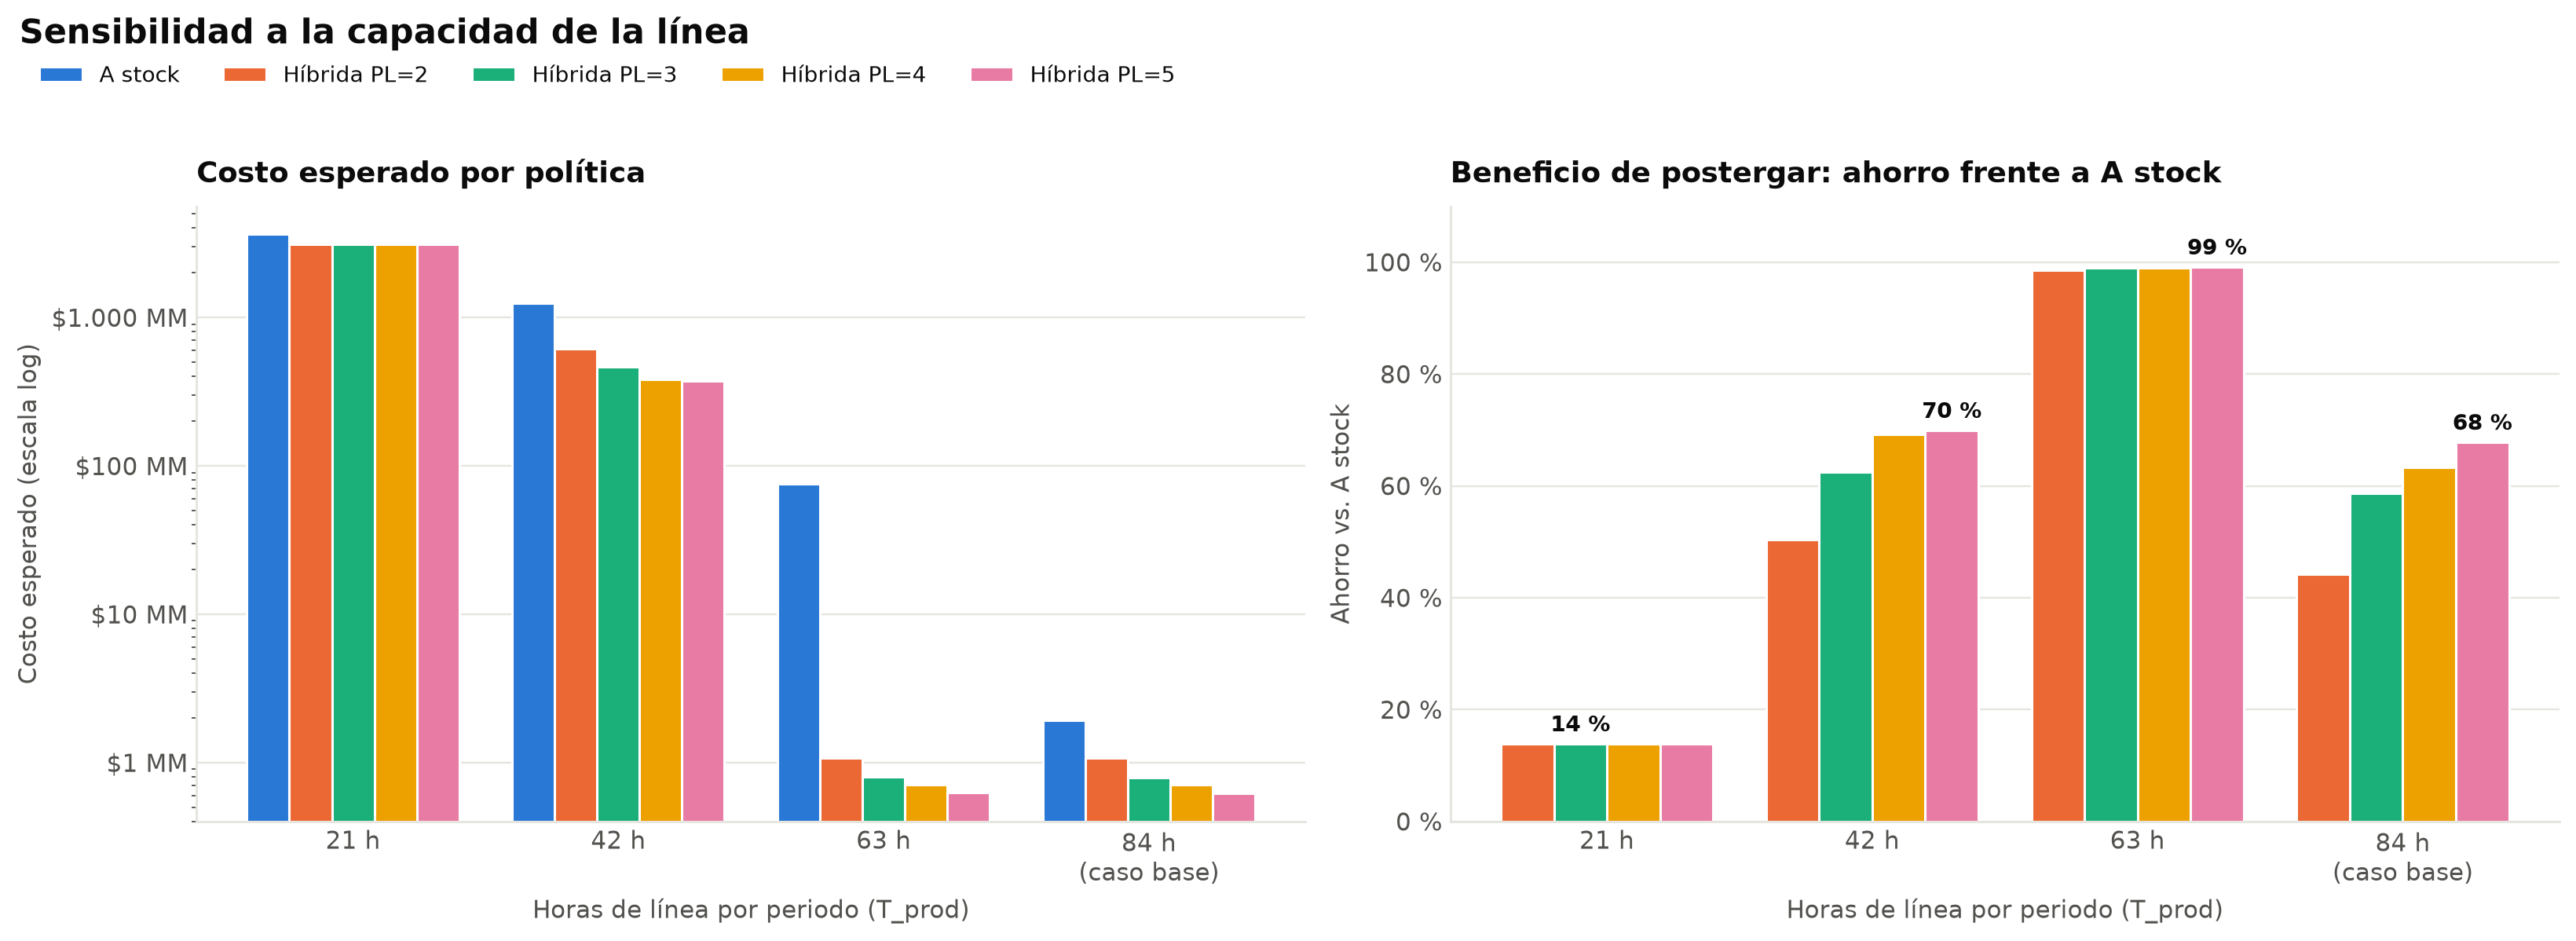

In [11]:
sens = modelo.sensibilidad('T_prod', valores=(21, 42, 63, 84), PLs=(0, 2, 3, 4, 5))
modelo.graficar_sensibilidad(sens, base=datos.PARAMS['T_prod']);

In [12]:
(sens / 1e6).style.format(lambda v: modelo._num(v, 2)).set_caption('Costo esperado (millones de $)')

,A stock,Híbrida PL=2,Híbrida PL=3,Híbrida PL=4,Híbrida PL=5
T_prod,,,,,
21,"3.628,33","3.123,59","3.123,59","3.123,59","3.123,59"
42,"1.240,13","615,31","465,39","382,11","372,62"
63,"75,57","1,07","0,80","0,71","0,62"
84,"1,92","1,07","0,79","0,70","0,62"


---
## 5. Conclusiones
1. **Postergar el etiquetado reduce mucho el costo.** Con la capacidad actual (84 h), pasar de *a stock* (\$1,92 MM) a *híbrida PL = 2* (\$1,07 MM) ahorra un **44 %**. Con *PL = 5* el ahorro llega a **68 %** (\$0,62 MM).
2. **El costo es casi todo inventario.** Los set-ups pesan menos de 2 %. Postergar evita guardar producto terminado de etiquetas que después no se venden.
3. **Contra pedido no es viable.** La línea no alcanza a producir todo en el periodo en que se pide, y los atrasos elevan el costo a ~\$1.861 MM.
4. **La postergación da robustez ante menos capacidad.** Con 63 h, *a stock* sube a \$75,6 MM por atrasos, mientras que las híbridas casi no cambian (\$0,6–1,1 MM). Con 42 h todas las políticas tienen atrasos, pero postergar 5 etiquetas reduce el costo un 70 % frente a *a stock* (\$373 MM vs. \$1.240 MM). Con 21 h la línea no da abasto: postergar más de 2 etiquetas ya no ayuda, porque todas las híbridas cuestan lo mismo (\$3.124 MM).
5. **Con PL = 2 no hay atrasos y la línea usa como máximo un 80 % de su capacidad (nodo 2)**, lo que deja holgura ante imprevistos.